# Geographical Origin Of Music

**Module:** IS71068B Data Programming - Coursework 1: Project proposal

**Author:** Mohammed A A Shoman

**Dataset:** Geographical Origin of Music (UCI Machine Learning Repository) - `default_features_1059_tracks.txt`

In this notebook we prepare the Geographical Origin of Music dataset for Coursework 2. The idea of the project is to see how well we can predict the latitude of a track's country from its audio features. Here we load the data, explore it, check its quality, decide what to do with the outliers, split it into training and test sets, choose 10 features and save the final data.

**AI use:** I used an AI assistant (Claude, by Anthropic) to explain some concepts and methods, to suggest, write and review code, and to help me write and edit the text. The assistant also made some edits directly in this notebook and ran it to check that all the cells work. I checked the code and all the results, and the final decisions in this notebook are mine.

## How to run this notebook

- The dataset file should be in the data folder, next to this notebook.
- The notebook needs the pandas, numpy and matplotlib libraries.
- You can run the cells one by one, or use Restart and Run All.


## 1. Introduction and research question

Every place has its own music, with different instruments, rhythms and ways of singing, so a song can tell us something about where it comes from. Usually experts decide this by listening to the music. Zhou et al. (2014) tried to do it with a computer, using only numbers measured from the audio. If this works, it is evidence that in this data the sound of the music is linked to its location, however it doesn't prove that the place causes the music to sound in a certain way.

Why I chose this topic: I am a Palestinian musician, singer, guitarist and music arranger/producer, and I also have a software engineering background. I am interested in how instruments, rhythms and singing styles are linked to musical traditions and to the places they come from. This project connects my experience in music with the data analysis skills I am learning. In the longer term I am interested in studying Palestinian music and song, however this coursework is only a small learning project using an international dataset, and it does not analyse Palestinian music.

Research question (for Coursework 2): how well can we predict the latitude of a track's country from its audio features?

We chose latitude (the north-south position) as our target, as it is one number between -90 and 90, so a simple regression model can be used to predict it.

Aims of this notebook:

- Get the dataset and explain where it comes from.
- Explore the data and check its quality.
- Prepare a clean dataset for Coursework 2 and explain every change.
- Think about the ethics of using this data.

Expected outcome: we don't know yet how well a model will predict latitude, this is the question for Coursework 2. Each feature alone has only a weak linear relation with latitude (Section 10), however this doesn't tell us how well several features will work together.

## 2. Background

This project is in the field of music information retrieval, which uses computers to analyse music (for example finding the genre or the mood of a song).

The dataset is from the study of Zhou et al. (2014):

- They collected 1,142 tracks of traditional and world music from 73 countries, from a personal collection. Western music was not included, as it spread everywhere and does not belong to one place.
- They only kept the countries with more than 10 tracks, so they ended up with 1,059 tracks from 33 countries, which is the file we use.
- The country of each track was taken from the CD notes (where the artist lives), and the track was given the latitude and longitude of the capital city of that country.
- The 68 audio features were extracted using a program called MARSYAS (Tzanetakis and Cook, 2000). They describe the timbre (the "colour" of the sound) of the whole track.
- They predicted the full location (latitude and longitude together) using K-nearest neighbours and random forest. The best average error was around 3,113 km, which is better than random guessing, so in their data there is some link between the music and its location.

The difference in our project: the original study looked at predicting the full location using more complex models. Our project has a smaller scope, we only predict latitude, and in Coursework 2 we start with a simple model. In this notebook the focus is on checking and preparing the data step by step, using the Python techniques we studied, and explaining why we did each change.

## 3. Data source, acquisition and licence

- Source: UCI Machine Learning Repository, dataset "Geographical Origin of Music" (Zhou, 2014). It was donated to UCI in 2014, and UCI currently lists it under the CC BY 4.0 licence (Creative Commons, n.d.).
- How we got it: we downloaded the files from the UCI website and saved them in the data folder, next to this notebook. The notebook reads the local file, so no internet is needed.
- The download has two files, we use default_features_1059_tracks.txt which has 68 features. The other file has 116 features, as it includes extra "chromatic" features about the musical notes. We chose the smaller one as we want to keep the number of features small.
- Each row is one track (song). The first 68 columns are the audio features and the last 2 columns are the latitude and longitude of the track's country (north and east are positive). The features have no names, so we named them feat_0 to feat_67. The features are summaries of the sound over the whole track, so the data is not a time series.
- The file is a text file with numbers separated by commas and without a header, which is basically a CSV file, so it is easy to load it into a pandas DataFrame and work with the numbers.
- Why this dataset: it fits my own interest in how music is linked to place (Section 1). The link between music and location is also an interesting question, the data is real and free to use, all of it is numbers, and it is small so it is easy to work with. Also the target (latitude) is a number, so it fits a regression project.

## 4. Setup

All the libraries we need are imported at the top. Constants (like the data file name) are also kept at the top, so they are easy to find and change.


In [1]:
# Imports and constants
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_FILE = "data/default_features_1059_tracks.txt"
RANDOM_SEED = 123

## 5. Loading the data

Before loading, we look at the first line of the raw file to see if it has a header and how the values are separated.


In [2]:
# Look at the raw file
with open(DATA_FILE) as f:
    first_line = f.readline()

print(first_line)
print("number of values in the first line: ", len(first_line.split(",")))

7.161286,7.835325,2.911583,0.984049,-1.499546,-2.094097,0.576,-1.205671,1.849122,-0.425598,-0.105672,1.728885,1.788986,0.849798,-1.109353,0.537904,-0.115368,5.069512,6.00771,0.820869,0.89619,0.131699,0.859286,2.059065,0.266773,1.192932,-1.421091,2.128661,-1.288109,1.458738,-0.734508,-0.092678,-0.571314,-0.142634,2.748619,3.099077,0.31727,-0.13058,2.048282,-0.173489,0.324616,-0.300817,0.471089,-0.538577,-0.979124,-0.679165,0.135963,-1.094049,-0.072197,-0.752002,-0.660715,1.319729,1.094839,-0.937659,-0.895371,-0.734962,0.441859,0.389178,-0.944584,-0.04361,-1.504263,0.351267,-1.018726,-0.174878,-1.089543,-0.66884,-0.914772,-0.83625,-15.75,-47.95

number of values in the first line:  70


In [3]:
# Load into a DataFrame and name the columns

feature_cols = [
    f"feat_{i}" for i in range(68)
]  # create list of names for the cols from index 0 to 67 using list comprehension

output_cols = ["latitude", "longitude"]  # from the UCI website

df = pd.read_csv(DATA_FILE, header=None, names=feature_cols + output_cols)

print(df.shape)
df.head()

(1059, 70)


,feat_0,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,feat_9,...,feat_60,feat_61,feat_62,feat_63,feat_64,feat_65,feat_66,feat_67,latitude,longitude
0,7.161286,7.835325,2.911583,0.984049,-1.499546,-2.094097,0.576000,-1.205671,1.849122,-0.425598,...,-1.504263,0.351267,-1.018726,-0.174878,-1.089543,-0.668840,-0.914772,-0.836250,-15.75,-47.95
1,0.225763,-0.094169,-0.603646,0.497745,0.874036,0.290280,-0.077659,-0.887385,0.432062,-0.093963,...,-0.495712,-0.465077,-0.157861,-0.157189,0.380951,1.088478,-0.123595,1.391141,14.91,-23.51
2,-0.692525,-0.517801,-0.788035,1.214351,-0.907214,0.880213,0.406899,-0.694895,-0.901869,-1.701574,...,-0.637167,0.147260,0.217914,2.718442,0.972919,2.081069,1.375763,1.063847,12.65,-8.00
3,-0.735562,-0.684055,2.058215,0.716328,-0.011393,0.805396,1.497982,0.114752,0.692847,0.052377,...,-0.178325,-0.065059,-0.724247,-1.020687,-0.751380,-0.385005,-0.012326,-0.392197,9.03,38.74
4,0.570272,0.273157,-0.279214,0.083456,1.049331,-0.869295,-0.265858,-0.401676,-0.872639,1.147483,...,-0.919463,-0.667912,-0.820172,-0.190488,0.306974,0.119658,0.271838,1.289783,34.03,-6.85


The first line has only numbers, so the file has no header. The values are separated by commas, and there are 70 values: 68 audio features + latitude + longitude. So we load it with header=None and give the columns our own names. The table has 1059 rows (tracks) and 70 columns.


## 6. Exploring the data

### 6.1 Structure and data types

All 70 columns are float64 (numbers), so there is no text or wrong data type, and we don't need to change any type.


In [4]:
# Structure and data types
df.info(verbose=False)  # brief instead of printing 70 lines


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1059 entries, 0 to 1058
Columns: 70 entries, feat_0 to longitude
dtypes: float64(70)
memory usage: 579.3 KB


### 6.2 Summary statistics

The feature means are between -0.069 and 0.032, and the standard deviations are between 0.907 and 1.023. So the means are around 0 and the SDs are around 1. This means the source already standardised the features (approximately, as they are not exactly 0 and 1), so we don't need to do it again.

The smallest value is -6.86 and the largest is 12.72, which is very far from the mean. So some features have extreme values. We check them in Section 8.

- Mean of a feature = (sum of all its values) / n, where n = 1059 tracks
- Standard deviation (SD) = √( Σ (x − mean)² / (n − 1) )
- pandas .std() divides by (n − 1).


In [5]:
# Summary statistics
features_means = df[
    feature_cols
].mean()  # only for the feature columns, exclude output columns
print(
    "features means:",
    features_means.min().round(3),
    "to",
    features_means.max().round(3),
)

features means: -0.069 to 0.032


In [6]:
features_SDs = df[feature_cols].std()  # same
print(
    "features standard deviations:",
    features_SDs.min().round(3),
    "to",
    features_SDs.max().round(3),
)


features standard deviations: 0.907 to 1.023


In [7]:
features_mins = df[feature_cols].min()
features_maxes = df[feature_cols].max()

print(
    "smallest value:",
    features_mins.min(),
    "| largest value:",
    features_maxes.max(),
)

smallest value: -6.856486 | largest value: 12.715904


Before dividing by the SD and by (max − min), we check that there are no infinite values and no constant features (a constant feature has SD = 0).

In [8]:
# Check for infinite values and constant features before dividing
print("Infinite values:", np.isinf(df.to_numpy()).sum())
print("Constant features:", (df[feature_cols].std() == 0).sum())

Infinite values: 0
Constant features: 0


Demo: min-max normalisation. Another way to scale the data is min-max normalisation, which puts every feature between 0 and 1:

x_new = (x − min) / (max − min)

We try it here only to compare with standardisation, the original data is not changed.

In [9]:
# Demo: min-max normalisation (in a new variable, the original data is not changed)
normalised = (df[feature_cols] - features_mins) / (features_maxes - features_mins)
print("smallest:", normalised.min().min(), "| largest:", normalised.max().max())
print("feat_54 mean after normalisation:", normalised["feat_54"].mean().round(3))
print("share of feat_54 values below 0.3:", (normalised["feat_54"] < 0.3).mean().round(3))


smallest: 0.0 | largest: 1.0
feat_54 mean after normalisation: 0.163
share of feat_54 values below 0.3: 0.984


After normalisation all values are between 0 and 1. However, feat_54 has one very big value (12.72) while most of its values are small, so after normalisation 98.4% of its values are squeezed below 0.3 and its mean is only 0.163. This example shows that min-max normalisation is very sensitive to extreme values, especially for feat_54. We don't add more scaling, as the features from the source are already approximately standardised (z-score, the same formula we use in Section 8.1), so we keep them as they are. Also, if we use any scaling in Coursework 2, the min and max (or mean and SD) should be calculated from the training set only, to avoid data leakage.

### 6.3 The target: latitude

Latitude is a continuous number, but in this dataset it has only 31 different values, because the coordinates are given by country, so all tracks from the same country have the same latitude.


In [10]:
# Latitude distribution
len(df["latitude"].unique())

31

Most tracks are from the north (positive latitude). Only 127 tracks (12%) are from the south (negative latitude).


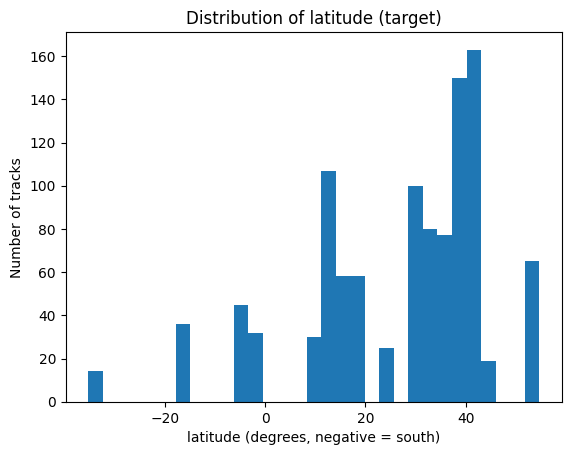

In [11]:
plt.hist(df["latitude"], bins=31)
plt.title("Distribution of latitude (target)")
plt.xlabel("latitude (degrees, negative = south)")
plt.ylabel("Number of tracks")
plt.show()

### 6.4 Tracks per location

The location with the most tracks has 69 (latitude 28.61, longitude 77.20), and the one with the fewest has 11 (latitude 17.25, longitude -88.76). The biggest is about 6 times the smallest (69 / 11 ≈ 6.3), so the data is not balanced.

There are 33 countries but only 31 different latitudes, because two pairs of countries have the same latitude.


In [12]:
# Tracks per location
location_counts = (
    df[["latitude", "longitude"]].value_counts()
)  # to count the totals in each country and order them from highest to lowest
len(location_counts)

33

In [13]:
location_counts.max()

np.int64(69)

In [14]:
location_counts.min()

np.int64(11)

In [15]:
location_counts.head()

latitude  longitude
28.61      77.20       69
12.65     -8.00        66
39.91      32.83       64
41.90      12.48       51
33.66      73.16       47
Name: count, dtype: int64

In [16]:
location_counts.tail()

latitude  longitude
 44.41     26.10       19
 35.70     139.71      19
 11.55     104.91      14
-35.30     149.12      14
 17.25    -88.76       11
Name: count, dtype: int64

## 7. Data quality checks

### 7.1 Missing values

There are no missing values. Also there are no symbols like "?" that mean a missing value, because all columns are float64 (Section 6.1).

Even though there are no missing values, this is what we would do if there were some:

- In a feature: fill it with the mean of the column (mean imputation). We don't remove the row, because some countries have only 11 tracks, so every track is important.
- In latitude: remove the whole row, because we can't guess the target.

Other options: fill the value using KNN (from similar tracks), or predict it with a regression model.


In [17]:
# Missing values
df.isna().sum().sum()  # check NaN values and return sum of every feature then return the sum of all sums.

np.int64(0)

Demo: we make a copy of the data, so the original data does not change. We put one fake missing value in the copy, then fill it with the column mean using a small function (fill_with_mean).

Mean imputation is a simple baseline, and we use it because we don't want to lose the track. However, it is not completely neutral: all the filled values get the same number, so the column can vary less than before, and its relation with other columns can change.

In [18]:
# demo example of missing data
demo = df.copy()
demo.loc[0, "feat_0"] = np.nan
demo.isna().sum().sum()

np.int64(1)

In [19]:
# Demo: fill missing values with the column mean, using a function and a loop
def fill_with_mean(column):
    filled = column.copy()  # don't change the original column
    mean = filled.mean()  # mean of the values that are not missing (NaN is skipped)
    if pd.isna(mean):
        raise ValueError("All values are missing, so the mean can't be calculated.")
    for i in filled.index:
        if pd.isna(filled.loc[i]):
            filled.loc[i] = mean
    return filled


demo["feat_0"] = fill_with_mean(demo["feat_0"])
demo.isna().sum().sum()

np.int64(0)

### 7.2 Duplicates

There are no exact duplicate rows (no two rows are completely identical), so nothing needs to be removed.

In [20]:
# Duplicates
df.duplicated().sum()

np.int64(0)

Demo: we add a copy of the first track to a copy of the data, then find it with duplicated() and remove it with drop_duplicates().

In [21]:
# Demo: add a copy of the first track, then find it and remove it
demo = pd.concat([df, df.head(1)])  # concat: join two tables
print("duplicates:", demo.duplicated().sum())
demo = demo.drop_duplicates()  # keeps only the first copy
print("duplicates after removing:", demo.duplicated().sum(), "| rows:", len(demo))

duplicates: 1
duplicates after removing: 0 | rows: 1059


### 7.3 Out-of-range and invalid values

All values are in the valid range: −90 ≤ latitude ≤ 90 and −180 ≤ longitude ≤ 180.

There are no infinite values (checked with np.isinf in Section 6.2).

There are no categorical (text) columns, so there is nothing to check here.


In [22]:
# Range and validity checks
df["latitude"].min()

np.float64(-35.3)

In [23]:
df["latitude"].max()

np.float64(54.68)

In [24]:
df["longitude"].min()

np.float64(-88.76)

In [25]:
df["longitude"].max()

np.float64(149.12)

Demo: we put a wrong latitude (120) in a copy of the data, then find it and remove the row. We remove the row and don't fix it, as there is no way to know the right latitude.

In [26]:
# Demo: put a wrong latitude (120) in a copy, then find it and remove it
demo = df.copy()
demo.loc[0, "latitude"] = 120
print("out-of-range rows:", ((demo["latitude"] < -90) | (demo["latitude"] > 90)).sum())
demo = demo[(demo["latitude"] >= -90) & (demo["latitude"] <= 90)]  # keep only the valid rows
print("rows after removing:", len(demo))

out-of-range rows: 1
rows after removing: 1058


## 8. Outliers

### 8.1 Detecting outliers

Rule: a value is flagged as an outlier if it is more than 3 standard deviations away from the mean of its column. This is called the three-sigma rule. In class the lecturer showed an example with 2.5 standard deviations, we use 3 as it is more conservative, so it flags fewer values.

- z = (x − mean) / SD
- outlier if |z| > 3, which is the same as abs(x − mean) / SD > 3

x is one value of a feature, and mean and SD are the mean and standard deviation of that feature (from Section 6.2).

McKinney (2022, ch. 7) shows a related example, where values with an absolute value above 3 are found in randomly generated standard normal data. Our calculation is a bit different, as we first calculate z with the mean and SD of each column.

In [27]:
# Detect outliers
z_scores = (
    df[feature_cols] - features_means
) / features_SDs  # how many SDs each value is from its column mean
is_outlier = np.abs(z_scores) > 3  # True/False table
print("outlier values:", is_outlier.sum().sum(), "out of", is_outlier.size)

outlier values: 981 out of 72012


In [28]:
is_outlier.any(axis=1).sum()  # any track has at least 1 outlier (any True in the row)

np.int64(353)

In [29]:
is_outlier.sum().sort_values(ascending=False).head()  # features with the most outliers

feat_48    29
feat_2     27
feat_34    24
feat_67    23
feat_11    22
dtype: int64

981 of the 72,012 values are flagged as outliers (981 / 72,012 ≈ 1.36%, where 72,012 = 1059 tracks × 68 features). They are spread over 353 tracks (33% of the tracks), in different features. The features with the most outliers are feat_48 (29), feat_2 (27) and feat_34 (24).

As a rough comparison (not a formal test of normality): in a normal distribution only about 0.27% of the values are more than 3 SDs from the mean, which would be about 194 values here. We have about 5 times more (981), so the features seem to have more extreme values than a normal distribution would have.


### 8.2 Deciding what to do with them

Decision: we keep all flagged values as they are.

- We found no evidence that they are errors. They may be real differences between tracks (for example a song with an unusual sound), however we can't be sure.
- We could remove them, but we chose not to, because removing every track with a flagged value would lose 353 tracks (a third of the data) without a strong reason, and some countries have only 11 tracks.
- We don't cap them (cut them to a limit like ±3) in the final data, because this changes the values and could hide real differences between countries, which is what we want to study. However, we also try capping on a copy of the training set in Section 10 to see if it changes the chosen features.
- They could still have a big effect on a linear regression model. We mention this as a limitation in Section 15, and their effect on prediction will be checked in Coursework 2.

## 9. Train/test split

Before choosing the features we split the data into a training set (80%) and a test set (20%), and the features are ranked using the training set only. If we use all the data, the test rows will affect the choice and the results in Coursework 2 will look better than they really are (data leakage; Kaufman et al., 2012).

We take 80% of the tracks from each country, so every country is in both sets. The random seed is fixed (123), so we get the same split every time we run the notebook.

In [30]:
# Train/test split
train = df.groupby(output_cols).sample(frac=0.8, random_state=RANDOM_SEED)
test = df.drop(train.index)

train.shape

(848, 70)

In [31]:
test.shape

(211, 70)

In [32]:
len(train[output_cols].value_counts())

33

In [33]:
len(test[output_cols].value_counts())

33

In [34]:
train["latitude"].mean().round(2)

np.float64(26.64)

In [35]:
test["latitude"].mean().round(2)

np.float64(26.71)

The training set has 848 tracks and the test set has 211 tracks, and all 33 countries are in both of them. The mean latitude is very similar in both (26.64 and 26.71), which is a useful simple check of the split.

## 10. Feature selection

68 features is a lot to look at and explain in a small project. The lecturer recommended keeping the scope of the project limited, so for now we keep only 10 features and remove the rest. The number 10 is our own choice to keep the project manageable, not a fixed rule, and we may change it in Coursework 2.

To choose them we use the Pearson correlation (r) between each feature and latitude, using the training set only. r is between -1 and 1, near 0 means little or no linear (straight-line) relation, and far from 0 (positive or negative) means a stronger linear relation. We sort the features by the absolute value of r, as we only care how far r is from 0, in the positive or the negative direction. Ranking features by their correlation with the target is a simple and common way to choose features (Guyon and Elisseeff, 2003). So we keep the 10 features with the highest absolute correlation with latitude in the training set.

r = Σ (x − mean_x) × (y − mean_y) / ( (n − 1) × SD_x × SD_y )

where x is the feature, y is latitude, and n is the number of training tracks.

In [36]:
# Feature selection
correlations = train[feature_cols].corrwith(train["latitude"])

In [37]:
top_10 = correlations.abs().sort_values(ascending=False).head(10)
top_10

feat_53    0.300267
feat_19    0.299208
feat_21    0.234845
feat_8     0.212797
feat_23    0.206340
feat_55    0.200252
feat_3     0.196882
feat_36    0.195196
feat_26    0.191945
feat_27    0.176246
dtype: float64

In [38]:
correlations.abs().sort_values(ascending=False).head(12).tail(3).round(3)  # the 10th, 11th and 12th features

feat_27    0.176
feat_2     0.172
feat_38    0.167
dtype: float64

In [39]:
selected_features = list(top_10.index)

In [40]:
correlations[selected_features].round(3)

feat_53   -0.300
feat_19   -0.299
feat_21   -0.235
feat_8    -0.213
feat_23   -0.206
feat_55   -0.200
feat_3    -0.197
feat_36   -0.195
feat_26   -0.192
feat_27   -0.176
dtype: float64

The 10 chosen features are feat_53, feat_19, feat_21, feat_8, feat_23, feat_55, feat_3, feat_36, feat_26 and feat_27. Their r is between -0.176 and -0.300, so each one alone has only a weak linear relation with latitude. This doesn't tell us how well the features will work together in a model, we will find this out in Coursework 2, and we may also try more features there.

All the 10 correlations are negative, when these features go up the latitude tends to go down a little (more to the south).

Other approach for the outliers: capping. In Section 8.2 we decided to keep the outliers. To check this decision, we try capping on a copy of the training set: every value above 3 becomes 3 and every value below -3 becomes -3. As the features are already approximately standardised, ±3 is roughly 3 SDs from the mean. Then we choose the top 10 features again and compare.

In [41]:
# Other approach for outliers: capping (on a copy, the original data is not changed)
train_capped = train.copy()
train_capped[feature_cols] = train_capped[feature_cols].clip(-3, 3)  # above 3 -> 3, below -3 -> -3
print("values changed:", (train[feature_cols] != train_capped[feature_cols]).sum().sum())

capped_correlations = train_capped[feature_cols].corrwith(train_capped["latitude"])
capped_top_10 = list(capped_correlations.abs().sort_values(ascending=False).head(10).index)
print("same features in both top 10:", len([f for f in capped_top_10 if f in selected_features]))
print(
    "new:",
    [f for f in capped_top_10 if f not in selected_features],
    "| removed:",
    [f for f in selected_features if f not in capped_top_10],
)

values changed: 768
same features in both top 10: 9
new: ['feat_2'] | removed: ['feat_27']


Capping changed 768 values in the training set, however 9 of the 10 chosen features are still the same, only feat_27 is replaced by feat_2, which was already very close to it (Section 15). This only shows that the list of chosen features is almost the same. It doesn't tell us if capping would change the predictions, the model coefficients or the performance of a model. So for now we keep the original values as we decided in Section 8.2, and in Coursework 2 we can compare the model with and without capping.

## 11. Final prepared dataset

Now we build the final data for Coursework 2. We keep only the 10 selected features and latitude (our target), and remove the other 58 features. Also we remove longitude, as it is not our target, and if we use it as an input it will tell the model the country of the track.

We save the training set and the test set in two separate CSV files. When we train a model later we will use only the training data, and we don't want to split the data again next time, so we keep both sets saved, train on the training file and then test using the test file. The same steps are done for both sets, so we put them in one function (save_dataset) instead of writing the same code two times. After saving, the function loads the file again to check that it was saved correctly (same shape, same columns, same values and no missing values).

We save the data as a CSV file (a flat file) and not in a database, as the data is small (1059 rows and 11 columns) and we only need to read it later, there is no need to add, update or delete rows many times. The original data file is not changed.

In [42]:
# Build, check and save the final dataset
def save_dataset(data, file_name):
    final = data[selected_features + ["latitude"]]
    final.to_csv(file_name, index=False)  # don't save index as separate column
    loaded = pd.read_csv(file_name)
    print(
        f"{file_name} | shape: {loaded.shape} | missing values: {loaded.isna().sum().sum()}"
    )
    print("Same columns:", list(loaded.columns) == list(final.columns))
    print("Same values:", np.allclose(loaded.to_numpy(), final.to_numpy()))
    return loaded


train_final = save_dataset(train, "data/train_prepared.csv")
test_final = save_dataset(test, "data/test_prepared.csv")

data/train_prepared.csv | shape: (848, 11) | missing values: 0
Same columns: True
Same values: True
data/test_prepared.csv | shape: (211, 11) | missing values: 0
Same columns: True
Same values: True


In [43]:
len(train_final)

848

In [44]:
len(test_final)

211

In [45]:
train_final.head()

,feat_53,feat_19,feat_21,feat_8,feat_23,feat_55,feat_3,feat_36,feat_26,feat_27,latitude
0,0.941446,0.299344,1.056223,0.463672,0.636948,2.087105,-0.297228,0.186294,0.486510,0.478223,-35.3
1,0.615374,1.399796,-1.112031,0.263640,-0.977599,-0.445123,-0.098273,1.313579,-0.533681,-0.465831,-35.3
2,1.059924,0.555272,0.675040,0.392935,1.023304,1.223103,-0.348908,1.324481,0.462116,0.365659,-35.3
3,-0.125139,3.046210,-0.360115,0.712438,0.959985,-0.674161,-0.137386,1.422473,0.762214,0.561699,-35.3
4,-0.102370,-0.806818,0.332118,-0.410684,-0.219681,1.819932,-0.826033,1.546346,0.268068,0.324623,-35.3


Both files were saved and loaded back correctly, with the same columns and the same values. The training file has 848 rows and the test file has 211 rows (848 + 211 = 1059, same as the original file). Each file has 11 columns (10 features + latitude) and no missing values.

## 12. Summary of changes to the data

This table shows all the changes we made to the data, and why.

| Change                                                                                                                | Reason                                                                                                      | Effect on the data                                                                                                     |
| --------------------------------------------------------------------------------------------------------------------- | ----------------------------------------------------------------------------------------------------------- | ---------------------------------------------------------------------------------------------------------------------- |
| Gave names to the columns (feat_0 to feat_67, latitude, longitude)                                                    | The file has no header                                                                                      | Same data, but easier to read and use                                                                                  |
| Checked missing values, exact duplicate rows, out-of-range values, infinite values and constant features              | To check the quality of the data (with a small demo for missing values, duplicates and out-of-range values) | Nothing was found, so no rows were changed or removed                                                                  |
| Kept the outliers as they are                                                                                         | We found no evidence that they are errors, and removing them would lose 353 tracks                          | All 1059 tracks are kept, their effect on the model will be checked in Coursework 2                                    |
| Split the data into a training set (80%) and a test set (20%) from each country, with a fixed seed (123)              | So the features are ranked using the training set only, and to use the same split in Coursework 2           | 848 training tracks and 211 test tracks, with all 33 countries in both (the countries are still not balanced)          |
| Kept the 10 features with the highest absolute correlation with latitude (training set only) and removed the other 58 | To keep the project small and manageable, as the lecturer recommended                                       | From 68 features to 10 features                                                                                        |
| Removed longitude                                                                                                     | It is not our target, and as an input it would tell the model the country                                   | Only latitude is left as the target                                                                                    |
| Saved the training set and the test set to two CSV files                                                              | To use the same prepared data in Coursework 2                                                               | train_prepared.csv (848 rows) and test_prepared.csv (211 rows), each with 11 columns. The original file is not changed |


## 13. Key findings

The main things we learned from the data:

- Our checks found no missing values, no exact duplicate rows, no infinite values, no constant features, and no latitude or longitude outside the valid range. The features were already approximately standardised by the source (mean around 0 and SD around 1), so we didn't rescale them.
- Latitude is a continuous number, but this data has only 31 different latitude values, as the coordinates are given by country, so all tracks from the same country have the same coordinates. Most of the tracks are from the north, only 127 tracks (12%) are from the south.
- The data is not balanced. The biggest country has 69 tracks and the smallest has 11, so the biggest is about 6 times the smallest, and some countries may affect the results more than others.
- The features have more extreme values than a normal distribution would have. 981 values (1.36%) are flagged as outliers, which is about 5 times more than the rough normal reference (0.27%). We found no evidence that they are errors, so we kept them, however they may affect a linear regression model, which we will check in Coursework 2.
- Each feature alone has only a weak linear relation with latitude, the strongest one has r = -0.30 only. All 10 chosen features have a negative r, so higher values tend to go with tracks from more southern countries. This doesn't tell us how well the features will predict latitude together, which is the question for Coursework 2.

## 14. Ethics

- The data was created by Fang Zhou and others (Zhou et al., 2014) and is shared on the UCI Machine Learning Repository, which currently lists it under the CC BY 4.0 licence (Creative Commons, n.d.). This licence allows us to use and change the data, but we have to credit the creators, give a link to the dataset and to the licence, and say what we changed. The creators and the links are in the References, and all our changes are in Section 12.
- Our two CSV files (train_prepared.csv and test_prepared.csv) are made from this dataset. If we share them, we should keep the credit to the creators, the link to the licence and a note of what we changed, and we should not add restrictions that the original licence doesn't allow. CC BY 4.0 doesn't require us to share our files under the same licence. The code and the analysis in this notebook are our work (AI use is explained at the top of the notebook).
- The file has no clear personal information, no names of artists, songs or albums, only numbers from the audio and the coordinates of a country. So the direct privacy risk is low, and we didn't need to hide or remove anything. Also the data doesn't include the music itself, only numbers, so the songs can't be played or copied from it.
- The brief says we can create a dummy dataset if the real data is sensitive. Our data has no clear personal or sensitive information and it is free to use, so there is no need for dummy data.
- The results could lead to harmful ideas, for example "music from country X always sounds like Y", which is a stereotype, as one country can have many different music styles. Also the data is from one personal collection and only 33 countries, so it doesn't show the music of the whole world. The results should not be used to guess where a person is from based on their music.
- The data file is in the data folder, next to the notebook, and every step (loading, checking, splitting, choosing features and saving) is in this notebook. The random seed is fixed, so anyone can run the notebook and get the same results. The original data file is never changed.

## 15. Discussion and limitations

The main weaknesses of the data and of our choices, and what we can do about them:

- The location is for the capital city, not for the song. The creators (Zhou et al., 2014) gave each track the latitude and longitude of the capital city of the artist's country, so all tracks from the same country have the same location, even if the music is from another part of the country. Big countries like India or China have many music styles but only one location.
- The target has only 31 different values, and two pairs of countries have the same latitude, so the model can't tell them apart. Also latitude is only half of the location (north-south only).
- The data is small and doesn't represent all music, only 1059 tracks from 33 countries, from one personal collection, and without Western music. So we can't say our results are true for all music.
- The countries are not balanced (11 to 69 tracks), so countries with more tracks may affect the model more. Our split keeps every country in both sets, but it doesn't fix this imbalance.
- We kept the outliers, as we found no evidence that they are errors, however they may have a big effect on some models like linear regression. In Coursework 2 we can compare the results with and without them (or with capping).
- The correlations are weak, and r only checks one feature at a time and only straight-line relations, so a feature with a low r could still be useful together with other features.
- The choice of the 10 features is not very stable. The 10th feature (feat_27, |r| = 0.176) and the 11th (feat_2, |r| = 0.172) are very close, so a different random split can change the last features in the list. In Coursework 2 we can compare our 10 features with more features or all 68.
- We don't know what each feature means, as the features have no names (feat_0 to feat_67), so it is hard to explain the results in musical terms.
- There are no artist or album names in the data, so songs from the same album may be in both the training and the test set, which can make the test results look a bit better than they really are.

## 16. Conclusion and further work

In this notebook we prepared the Geographical Origin of Music dataset for Coursework 2. We loaded the data, explored it and checked its quality. Our checks found no missing values, no exact duplicate rows and no invalid coordinates, so there was no need to remove or fix any values. We kept the outliers, as we found no evidence that they are errors, but their effect on the model still needs to be checked. Then we split the data into a training set and a test set from each country, chose the 10 features with the highest absolute correlation with latitude using the training set only, and saved the final data in two CSV files.

The main thing we learned is that each feature alone has only a weak linear relation with latitude. How well the features work together is still an open question for Coursework 2, and it is interesting to see how much the music can tell about its location.

Plan for Coursework 2:

- Load train_prepared.csv and train a multiple linear regression model (a linear regression with several features) to predict latitude.
- Compare the model with a simple baseline that always predicts the mean latitude of the training set. If this model is not better than the baseline, it means this model doesn't use the features well, but it doesn't prove that the features have no useful information for other models.
- Use test_prepared.csv only once at the end, to measure the error on tracks the model has never seen, using the Root Mean Squared Error (RMSE), which is in degrees.
- We may try more features (or all 68), and check if keeping or capping the outliers changes the results. The random seed is fixed, so we can make the same split again.

Further work: we could also predict longitude to get the full location, or try the bigger file with 116 features (default_plus_chromatic_features_1059_tracks.txt).

## 17. Programming techniques used

We used pandas for most of the work as it makes working with tables easy, NumPy for the maths, and matplotlib for the chart. Most of these techniques are explained in McKinney (2022).

| Technique | Where | What we used it for |
| --------- | ----- | ------------------- |
| Constants at the top (DATA_FILE, RANDOM_SEED) | Section 4 | Easy to find and change, and the same random split every time |
| Reading a file with open() and readline() | Section 5 | Looking at the raw file before loading it |
| List comprehension and split() | Section 5 | Making the 68 column names, and counting the values in the first line |
| read_csv() with header=None and names | Section 5 | Loading the file into a DataFrame with our own column names |
| info(), mean(), std(), min(), max(), unique(), value_counts(), head(), tail() | Sections 6 and 9 | Exploring the features, the target and the number of tracks per country |
| np.isinf() and std() == 0 | Section 6.2 | Checking for infinite values and constant features before dividing |
| Min-max normalisation with vectorised maths | Section 6.2 | A demo to compare it with the standardisation that the source already did |
| Histogram with matplotlib (plt.hist) | Section 6.3 | Showing the distribution of latitude |
| isna(), copy(), loc, and a function with a for loop (fill_with_mean) | Section 7.1 | Checking for missing values, and a demo of filling a missing value with the column mean |
| duplicated() | Section 7.2 | Checking for exact duplicate rows |
| concat() and drop_duplicates() | Section 7.2 | A demo of finding and removing a duplicate row |
| Filtering rows with True/False conditions | Section 7.3 | A demo of finding and removing a wrong latitude |
| Vectorised maths with pandas and NumPy (z-scores, np.abs, True/False tables, any()) | Section 8 | Finding the outliers in all 72,012 values at once, without loops |
| groupby(), sample() with a random seed, and drop() | Section 9 | Taking 80% of the tracks from each location for training, and the rest for testing |
| corrwith(), abs() and sort_values() | Section 10 | Ranking the features by their correlation with latitude and choosing the top 10 |
| clip() | Section 10 | Capping the outliers on a copy, to compare it with keeping them |
| A function (def save_dataset) | Section 11 | Doing the same steps (select, save, load, check) for the training and test sets without repeating the code |
| to_csv(), read_csv() and f-strings | Section 11 | Saving the final data and printing the checks |
| np.allclose() and comparing the lists of columns | Section 11 | Checking that the saved file has the same columns and values |
| Markdown cells | All sections | Explaining each step and each decision |


## 18. References

Anthropic (2026) _Claude_ [AI assistant]. Available at: https://claude.ai (Accessed: 10 November 2026).

Creative Commons (n.d.) _Attribution 4.0 International (CC BY 4.0)_. Available at: https://creativecommons.org/licenses/by/4.0/ (Accessed: 10 November 2026).

Guyon, I. and Elisseeff, A. (2003) 'An introduction to variable and feature selection', _Journal of Machine Learning Research_, 3, pp. 1157–1182. Available at: https://jmlr.org/papers/v3/guyon03a.html (Accessed: 10 November 2026).

Kaufman, S., Rosset, S., Perlich, C. and Stitelman, O. (2012) 'Leakage in data mining: formulation, detection, and avoidance', _ACM Transactions on Knowledge Discovery from Data_, 6(4), Article 15, pp. 1–21. doi:10.1145/2382577.2382579.

McKinney, W. (2022) _Python for Data Analysis: Data Wrangling with pandas, NumPy, and Jupyter_. 3rd edn. Sebastopol, CA: O'Reilly Media.

Tzanetakis, G. and Cook, P. (2000) 'MARSYAS: a framework for audio analysis', _Organised Sound_, 4(3), pp. 169–175. doi:10.1017/S1355771800003071.

Zhou, F. (2014) _Geographical Origin of Music_ [Dataset]. UCI Machine Learning Repository. doi:10.24432/C5VK5D.

Zhou, F., Claire, Q. and King, R.D. (2014) 'Predicting the geographical origin of music', in _2014 IEEE International Conference on Data Mining_. IEEE, pp. 1115–1120. doi:10.1109/ICDM.2014.73.
